In [1]:
from google.colab import drive
import pandas as pd

# Mount Google Drive to /content/drive
drive.mount('/content/drive')

# Define the path to your CSV file in Google Drive
file_path = '/content/drive/MyDrive/Manthan/creditcard.csv'

try:
    # Read the CSV file into a pandas DataFrame
    df = pd.read_csv(file_path)
    print("CSV file loaded successfully!")
    print(df.head())
except Exception as e:
    print(f"An error occurred: {e}")

Mounted at /content/drive
CSV file loaded successfully!
   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458 

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configure visual settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (14, 10)

/tmp/ipykernel_1965/3471267309.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x='Class', data=df, palette='Set1')


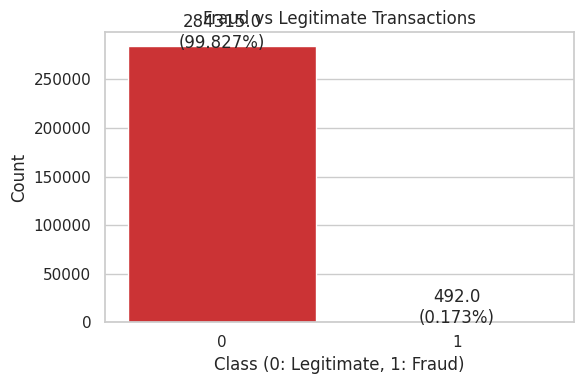

In [3]:
# 1. Transaction Distribution / Fraud vs Legitimate
plt.figure(figsize=(6, 4))
ax = sns.countplot(x='Class', data=df, palette='Set1')
plt.title('Fraud vs Legitimate Transactions')
plt.xlabel('Class (0: Legitimate, 1: Fraud)')
plt.ylabel('Count')
for p in ax.patches:
    ax.annotate(f'{p.get_height()}\n({p.get_height()/len(df)*100:.3f}%)',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 10), textcoords='offset points')
plt.tight_layout()
plt.show()

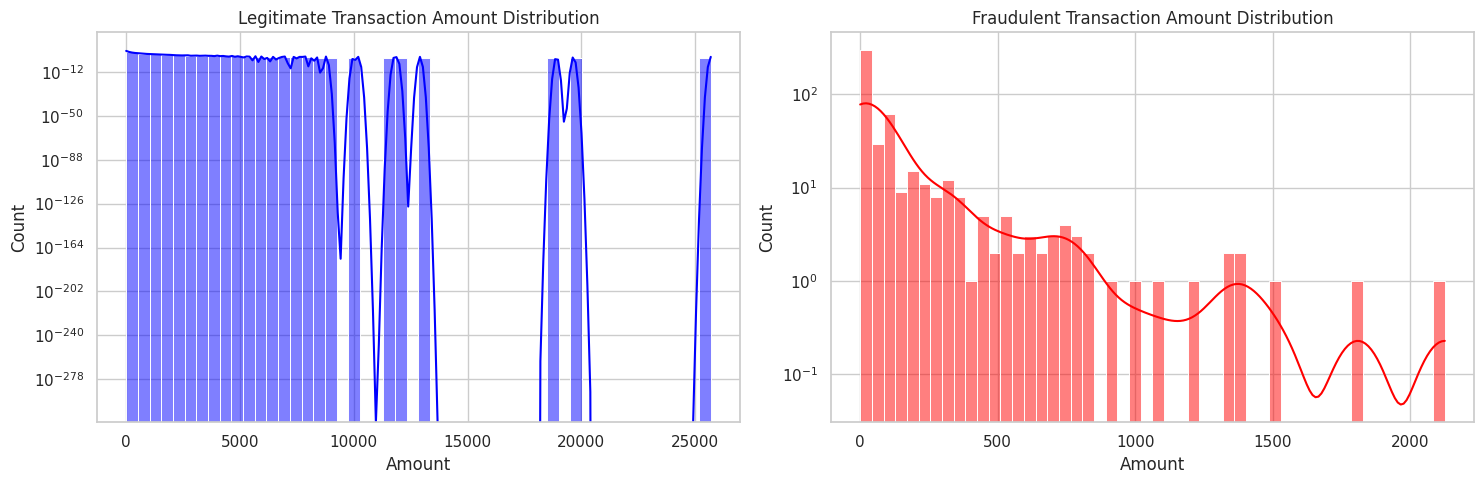

--- Legitimate Transactions Amount Stats ---
count    284315.000000
mean         88.291022
std         250.105092
min           0.000000
25%           5.650000
50%          22.000000
75%          77.050000
max       25691.160000
Name: Amount, dtype: float64

--- Fraudulent Transactions Amount Stats ---
count     492.000000
mean      122.211321
std       256.683288
min         0.000000
25%         1.000000
50%         9.250000
75%       105.890000
max      2125.870000
Name: Amount, dtype: float64


In [4]:
# 2. Transaction Amount Distribution
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
sns.histplot(df[df['Class'] == 0]['Amount'], bins=50, ax=ax1, kde=True, color='blue')
ax1.set_title('Legitimate Transaction Amount Distribution')
ax1.set_yscale('log')

sns.histplot(df[df['Class'] == 1]['Amount'], bins=50, ax=ax2, kde=True, color='red')
ax2.set_title('Fraudulent Transaction Amount Distribution')
ax2.set_yscale('log')
plt.tight_layout()
plt.show()

# Print basic stats for Amount
print("--- Legitimate Transactions Amount Stats ---")
print(df[df['Class'] == 0]['Amount'].describe())
print("\n--- Fraudulent Transactions Amount Stats ---")
print(df[df['Class'] == 1]['Amount'].describe())

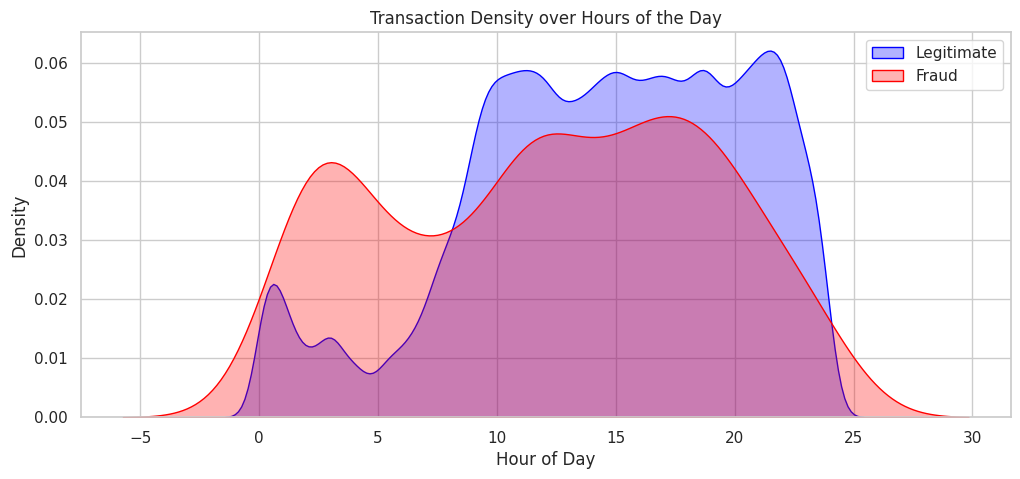

In [5]:
# 3. Time-based Transaction Patterns
# The 'Time' column is seconds elapsed since the first transaction
# Let's convert to hour of the day (assuming 48 hours dataset cycle)
df['Hour'] = (df['Time'] / 3600) % 24

plt.figure(figsize=(12, 5))
sns.kdeplot(df[df['Class'] == 0]['Hour'], label='Legitimate', fill=True, color='blue', alpha=0.3)
sns.kdeplot(df[df['Class'] == 1]['Hour'], label='Fraud', fill=True, color='red', alpha=0.3)
plt.title('Transaction Density over Hours of the Day')
plt.xlabel('Hour of Day')
plt.ylabel('Density')
plt.legend()
plt.show()

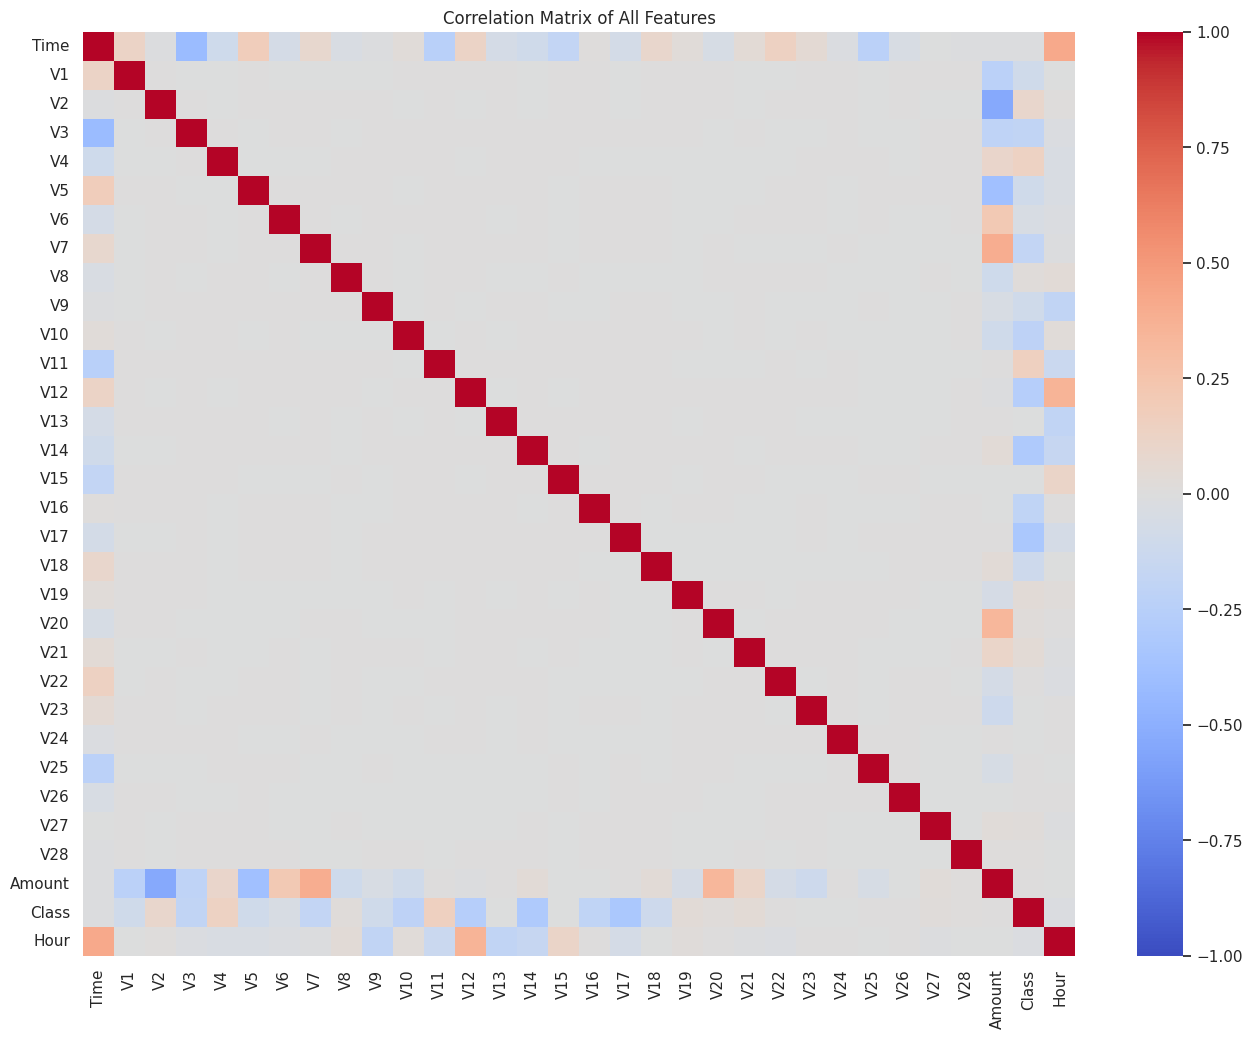

In [6]:
# 4. Correlation analysis of anonymized features (V1-V28)
plt.figure(figsize=(16, 12))
corr = df.corr()
sns.heatmap(corr, cmap='coolwarm', annot=False, vmin=-1, vmax=1, fmt=".2f")
plt.title('Correlation Matrix of All Features')
plt.show()


--- Top negatively correlated features with Class ---
V17   -0.326481
V14   -0.302544
V12   -0.260593
V10   -0.216883
Name: Class, dtype: float64

--- Top positively correlated features with Class ---
V21      0.040413
V2       0.091289
V4       0.133447
V11      0.154876
Class    1.000000
Name: Class, dtype: float64


/tmp/ipykernel_1965/2750184289.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Class', y='V17', data=df, ax=axes[0], palette='Set2')
/tmp/ipykernel_1965/2750184289.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Class', y='V14', data=df, ax=axes[1], palette='Set2')
/tmp/ipykernel_1965/2750184289.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Class', y='V11', data=df, ax=axes[2], palette='Set2')
/tmp/ipykernel_1965/2750184289.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be r

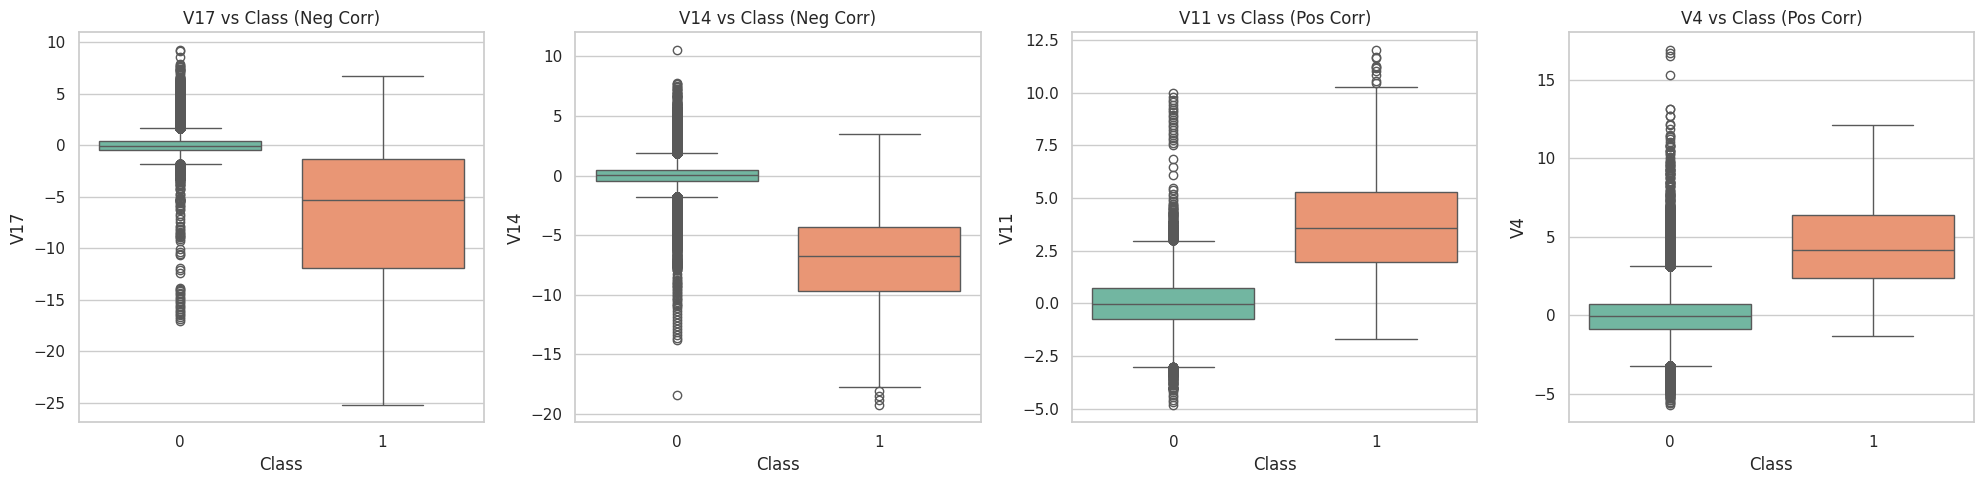

In [7]:
# 5. Fraud-related feature distributions (Highly correlated features with Class)
# Let's find top features negatively & positively correlated with Class
class_corr = corr['Class'].sort_values()
print("\n--- Top negatively correlated features with Class ---")
print(class_corr.head(4))
print("\n--- Top positively correlated features with Class ---")
print(class_corr.tail(5)) # Class itself will be 1.0

# Visualize some highly correlated features
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
sns.boxplot(x='Class', y='V17', data=df, ax=axes[0], palette='Set2')
axes[0].set_title('V17 vs Class (Neg Corr)')

sns.boxplot(x='Class', y='V14', data=df, ax=axes[1], palette='Set2')
axes[1].set_title('V14 vs Class (Neg Corr)')

sns.boxplot(x='Class', y='V11', data=df, ax=axes[2], palette='Set2')
axes[2].set_title('V11 vs Class (Pos Corr)')

sns.boxplot(x='Class', y='V4', data=df, ax=axes[3], palette='Set2')
axes[3].set_title('V4 vs Class (Pos Corr)')
plt.tight_layout()
plt.show()

In [8]:
# 6. Outlier Analysis (using IQR on a key correlated feature V14 for fraud class)
v14_fraud = df[df['Class'] == 1]['V14'].values
q25, q75 = np.percentile(v14_fraud, 25), np.percentile(v14_fraud, 75)
iqr = q75 - q25
cut_off = iqr * 1.5
lower, upper = q25 - cut_off, q75 + cut_off

outliers = [x for x in v14_fraud if x < lower or x > upper]
print(f"\n--- Outlier analysis for V14 in Fraud transactions ---")
print(f"IQR: {iqr:.4f}")
print(f"Lower Bound: {lower:.4f}, Upper Bound: {upper:.4f}")
print(f"Number of outliers detected: {len(outliers)}")


--- Outlier analysis for V14 in Fraud transactions ---
IQR: 5.4099
Lower Bound: -17.8076, Upper Bound: 3.8320
Number of outliers detected: 4


In [9]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

print("=== Phase 2: Data Preprocessing ===\n")

=== Phase 2: Data Preprocessing ===



In [10]:
# 1. Duplicate Analysis & Removal
initial_rows = df.shape[0]
duplicates_count = df.duplicated().sum()
print(f"Initial number of rows: {initial_rows}")
print(f"Number of duplicate rows found: {duplicates_count}")

# Drop duplicates
df_cleaned = df.drop_duplicates()
print(f"Rows after removing duplicates: {df_cleaned.shape[0]}\n")

Initial number of rows: 284807
Number of duplicate rows found: 1081
Rows after removing duplicates: 283726



In [11]:
# 2. Missing-value Checks
missing_values = df_cleaned.isnull().sum().sum()
print(f"Total missing values in the dataset: {missing_values}\n")

Total missing values in the dataset: 0



In [12]:
# 3. Time Feature Transformation
# Transforming Time (seconds) into a cyclical feature (Hour of Day) to capture periodic patterns
df_cleaned = df_cleaned.copy()
df_cleaned['Hour'] = (df_cleaned['Time'] / 3600) % 24
df_cleaned['Hour_sin'] = np.sin(2 * np.pi * df_cleaned['Hour'] / 24)
df_cleaned['Hour_cos'] = np.cos(2 * np.pi * df_cleaned['Hour'] / 24)

# Drop original Time and intermediate Hour columns
df_preprocessed = df_cleaned.drop(columns=['Time', 'Hour'])

In [13]:
# 4. Train/Test Split (Stratified to maintain class ratios)
X = df_preprocessed.drop(columns=['Class'])
y = df_preprocessed['Class']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("--- Train/Test Split Ratios ---")
print(f"X_train shape: {X_train.shape}, Class 1 count: {sum(y_train)} ({sum(y_train)/len(y_train)*100:.3f}%)")
print(f"X_test shape: {X_test.shape}, Class 1 count: {sum(y_test)} ({sum(y_test)/len(y_test)*100:.3f}%)\n")

--- Train/Test Split Ratios ---
X_train shape: (226980, 31), Class 1 count: 378 (0.167%)
X_test shape: (56746, 31), Class 1 count: 95 (0.167%)



In [14]:
# 5. Preprocessing & Imbalance Handling Pipeline
# Amount contains extreme outliers, hence RobustScaler is preferred over StandardScaler
numeric_features = ['Amount']
remaining_features = [col for col in X_train.columns if col != 'Amount']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', RobustScaler(), numeric_features)
    ],
    remainder='passthrough' # Leave V1-V28 and cyclical Time sin/cos features untouched
)

# To handle class imbalance without leakage, we use imblearn's pipeline
# which applies SMOTE only during fit (training) and not during predict (testing)
preprocessing_pipeline = ImbPipeline(steps=[
    ('preprocessor', preprocessor),
    ('smote', SMOTE(random_state=42))
])

# Fit and transform the training data using the preprocessing and SMOTE pipeline
X_train_resampled, y_train_resampled = preprocessing_pipeline.fit_resample(X_train, y_train)

# Transform the testing data (Note: We do NOT apply SMOTE to the test set to maintain evaluation validity)
X_test_scaled = preprocessor.transform(X_test)

print("--- Preprocessing & Resampling Completed ---")
print(f"Resampled X_train shape: {X_train_resampled.shape}")
print(f"Resampled y_train shape (class distribution): {np.bincount(y_train_resampled)}")
print(f"Scaled X_test shape: {X_test_scaled.shape}")

--- Preprocessing & Resampling Completed ---
Resampled X_train shape: (453204, 31)
Resampled y_train shape (class distribution): [226602 226602]
Scaled X_test shape: (56746, 31)


In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

print("=== Phase 3: Feature Engineering ===\n")

=== Phase 3: Feature Engineering ===



In [16]:
# Working with a copy of the preprocessed DataFrame to engineer new features safely
df_fe = df_cleaned.copy()

# 1. Transaction Time Intervals (Time difference between consecutive transactions)
# First, sort by Time to ensure chronological order
df_fe = df_fe.sort_values(by='Time')
df_fe['Time_Delta'] = df_fe['Time'].diff().fillna(0)

In [17]:
# 2. Time-of-day indicators
# Let's group hours into 4 main shifts: Night (0-6), Morning (6-12), Afternoon (12-18), Evening (18-24)
def get_time_of_day(hour):
    if 0 <= hour < 6:
        return 'Night'
    elif 6 <= hour < 12:
        return 'Morning'
    elif 12 <= hour < 18:
        return 'Afternoon'
    else:
        return 'Evening'

df_fe['Time_Of_Day'] = df_fe['Hour'].apply(get_time_of_day)
# One-hot encode Time_Of_Day
df_fe = pd.get_dummies(df_fe, columns=['Time_Of_Day'], drop_first=True)

In [18]:
# 3. Amount-related transformations
# Since Amount has extreme values, a log transform (with offset) stabilizes variance
df_fe['Log_Amount'] = np.log1p(df_fe['Amount'])

In [19]:
# 4. Transformations of anonymized features
# V17 and V14 were highly negatively correlated with Class.
# V11 and V4 were highly positively correlated with Class.
# Creating interaction features between top negative and top positive features
df_fe['V17_x_V14'] = df_fe['V17'] * df_fe['V14']
df_fe['V11_x_V4'] = df_fe['V11'] * df_fe['V4']

# Drop non-numeric and intermediate keys for modeling validation
# (Time, Hour, and original Class will be separated)
X_fe = df_fe.drop(columns=['Class', 'Time', 'Hour'])
y_fe = df_fe['Class']

# Convert any remaining boolean columns to int
bool_cols = X_fe.select_dtypes(include=['bool']).columns
X_fe[bool_cols] = X_fe[bool_cols].astype(int)

print("Engineered Features:")
print(list(X_fe.columns[-7:]))

Engineered Features:
['Time_Delta', 'Time_Of_Day_Evening', 'Time_Of_Day_Morning', 'Time_Of_Day_Night', 'Log_Amount', 'V17_x_V14', 'V11_x_V4']



--- Validating Feature Importance --- 

Top 15 Most Important Features:
V12          0.174866
V17          0.119903
V14          0.100764
V17_x_V14    0.100708
V16          0.043820
V10          0.043755
V11_x_V4     0.038279
V7           0.025626
V11          0.024736
V4           0.024140
V26          0.020664
Hour_sin     0.018793
V1           0.018571
V6           0.017768
V9           0.015218
dtype: float64


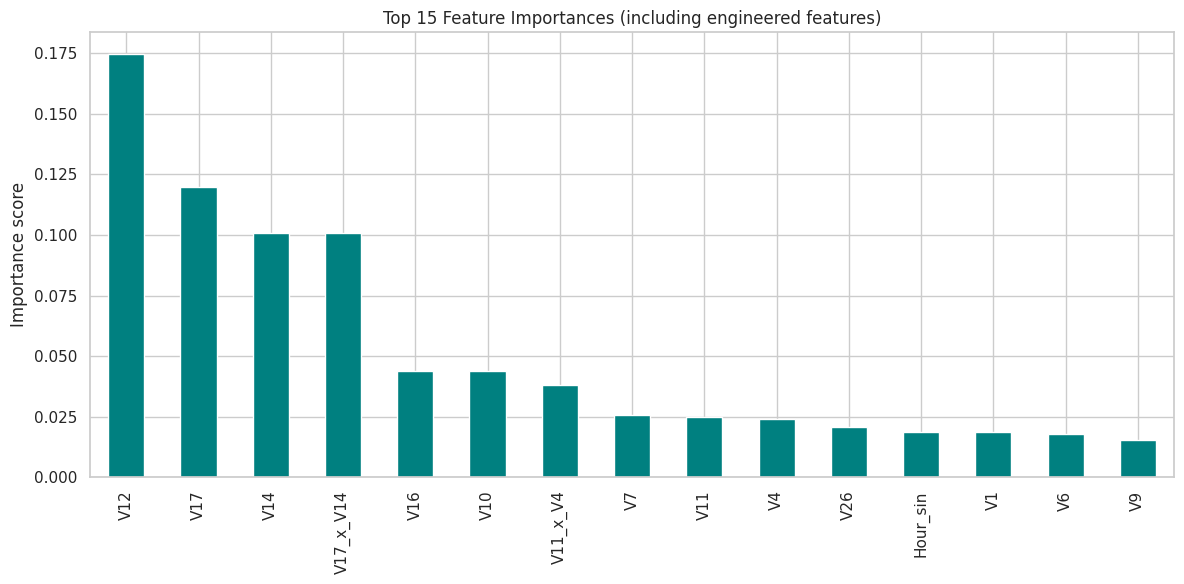

In [20]:
# 5. Feature Validation using Random Forest Importance
print("\n--- Validating Feature Importance --- ")
# Take a stratified subset to speed up the Random Forest computation
X_sample, _, y_sample, _ = train_test_split(
    X_fe, y_fe, test_size=0.8, random_state=42, stratify=y_fe
)

rf = RandomForestClassifier(n_estimators=50, random_state=42, n_jobs=-1)
rf.fit(X_sample, y_sample)

# Map feature importances
importances = pd.Series(rf.feature_importances_, index=X_fe.columns).sort_values(ascending=False)

# Display top 15 features, ensuring we check our newly engineered features
print("\nTop 15 Most Important Features:")
print(importances.head(15))

# Plot feature importances
plt.figure(figsize=(12, 6))
importances.head(15).plot(kind='bar', color='teal')
plt.title('Top 15 Feature Importances (including engineered features)')
plt.ylabel('Importance score')
plt.tight_layout()
plt.show()

In [21]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix

print("=== Credit Card Fraud Model Building ===\n")

=== Credit Card Fraud Model Building ===



In [22]:
# 1. Logistic Regression
print("Training Logistic Regression...")
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_resampled, y_train_resampled)
lr_preds = lr_model.predict(X_test_scaled)
lr_probs = lr_model.predict_proba(X_test_scaled)[:, 1]

Training Logistic Regression...


In [23]:
# 2. Random Forest
print("Training Random Forest (this may take a minute)...")
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train_resampled, y_train_resampled)
rf_preds = rf_model.predict(X_test_scaled)
rf_probs = rf_model.predict_proba(X_test_scaled)[:, 1]

Training Random Forest (this may take a minute)...


KeyboardInterrupt: 

In [24]:
# 3. XGBoost
print("Training XGBoost...")
xgb_model = XGBClassifier(random_state=42, use_label_encoder=False, eval_metric='logloss')
xgb_model.fit(X_train_resampled, y_train_resampled)
xgb_preds = xgb_model.predict(X_test_scaled)
xgb_probs = xgb_model.predict_proba(X_test_scaled)[:, 1]

Training XGBoost...


/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [09:17:58] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


In [26]:
# Evaluation Helper Function
def evaluate_model(name, y_true, y_pred, y_prob):
    print(f"\n================ {name} Evaluation ================")
    print(classification_report(y_true, y_pred, target_names=['Legitimate', 'Fraud']))
    print(f"ROC AUC Score: {roc_auc_score(y_true, y_prob):.4f}")
    cm = confusion_matrix(y_true, y_pred)
    print("Confusion Matrix:")
    print(f"  True Legitimate: {cm[0][0]} | False Fraud: {cm[0][1]}")
    print(f"  False Legitimate: {cm[1][0]} | True Fraud: {cm[1][1]}")

# Execute Evaluations
evaluate_model("Logistic Regression", y_test, lr_preds, lr_probs)
# evaluate_model("Random Forest", y_test, rf_preds, rf_probs)
evaluate_model("XGBoost", y_test, xgb_preds, xgb_probs)


================ Logistic Regression Evaluation ================
              precision    recall  f1-score   support

  Legitimate       1.00      0.97      0.99     56651
       Fraud       0.05      0.87      0.10        95

    accuracy                           0.97     56746
   macro avg       0.53      0.92      0.54     56746
weighted avg       1.00      0.97      0.99     56746

ROC AUC Score: 0.9631
Confusion Matrix:
  True Legitimate: 55179 | False Fraud: 1472
  False Legitimate: 12 | True Fraud: 83

================ XGBoost Evaluation ================
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     56651
       Fraud       0.83      0.80      0.81        95

    accuracy                           1.00     56746
   macro avg       0.91      0.90      0.91     56746
weighted avg       1.00      1.00      1.00     56746

ROC AUC Score: 0.9652
Confusion Matrix:
  True Legitimate: 56635 | False Fraud: 16
  False Legitimate

=== Phase 5: Comprehensive Model Evaluation ===



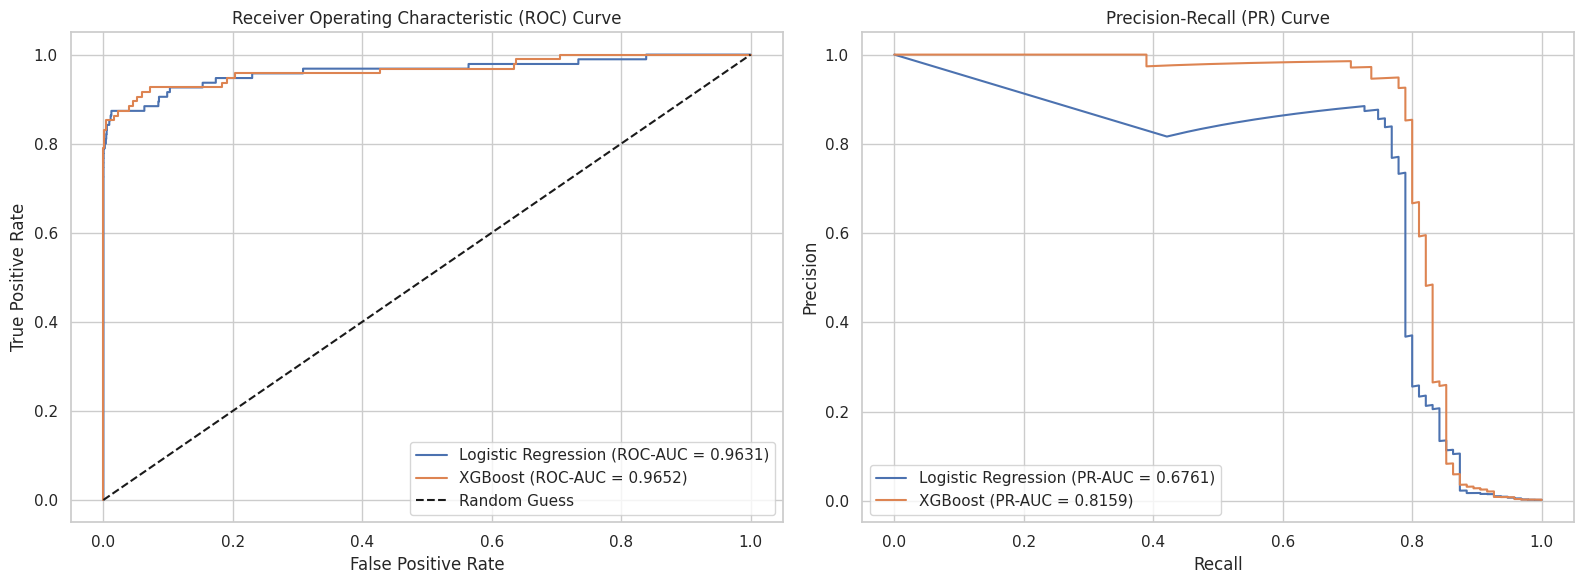


--- Threshold Impact Analysis for Logistic Regression ---
Threshold: 0.30 | Precision: 0.0258 | Recall: 0.8737 | F1-Score: 0.0500
  Confusion Matrix -> TP: 83, FP: 3139, FN: 12, TN: 53512
Threshold: 0.50 | Precision: 0.0534 | Recall: 0.8737 | F1-Score: 0.1006
  Confusion Matrix -> TP: 83, FP: 1472, FN: 12, TN: 55179
Threshold: 0.70 | Precision: 0.0961 | Recall: 0.8737 | F1-Score: 0.1731
  Confusion Matrix -> TP: 83, FP: 781, FN: 12, TN: 55870

--- Threshold Impact Analysis for XGBoost ---
Threshold: 0.30 | Precision: 0.7308 | Recall: 0.8000 | F1-Score: 0.7638
  Confusion Matrix -> TP: 76, FP: 28, FN: 19, TN: 56623
Threshold: 0.50 | Precision: 0.8261 | Recall: 0.8000 | F1-Score: 0.8128
  Confusion Matrix -> TP: 76, FP: 16, FN: 19, TN: 56635
Threshold: 0.70 | Precision: 0.9250 | Recall: 0.7789 | F1-Score: 0.8457
  Confusion Matrix -> TP: 74, FP: 6, FN: 21, TN: 56645


In [27]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_curve,
    auc,
    precision_recall_curve,
    average_precision_score
)

print("=== Phase 5: Comprehensive Model Evaluation ===\n")

def plot_evaluation_curves(models_dict, y_true):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

    for name, probs in models_dict.items():
        # 1. ROC Curve
        fpr, tpr, _ = roc_curve(y_true, probs)
        roc_auc = auc(fpr, tpr)
        ax1.plot(fpr, tpr, label=f'{name} (ROC-AUC = {roc_auc:.4f})')

        # 2. Precision-Recall Curve
        precision, recall, _ = precision_recall_curve(y_true, probs)
        pr_auc = average_precision_score(y_true, probs)
        ax2.plot(recall, precision, label=f'{name} (PR-AUC = {pr_auc:.4f})')

    ax1.plot([0, 1], [0, 1], 'k--', label='Random Guess')
    ax1.set_xlabel('False Positive Rate')
    ax1.set_ylabel('True Positive Rate')
    ax1.set_title('Receiver Operating Characteristic (ROC) Curve')
    ax1.legend(loc='lower right')

    ax2.set_xlabel('Recall')
    ax2.set_ylabel('Precision')
    ax2.set_title('Precision-Recall (PR) Curve')
    ax2.legend(loc='lower left')

    plt.tight_layout()
    plt.show()

# Prepare the probabilities of the trained models
active_models_probs = {
    "Logistic Regression": lr_probs,
    "XGBoost": xgb_probs
}

# Plot ROC and PR Curves
plot_evaluation_curves(active_models_probs, y_test)

# Threshold impact examination
def evaluate_at_thresholds(name, y_true, y_probs, thresholds=[0.3, 0.5, 0.7]):
    print(f"\n--- Threshold Impact Analysis for {name} ---")
    for thresh in thresholds:
        y_pred_thresh = (y_probs >= thresh).astype(int)
        cm = confusion_matrix(y_true, y_pred_thresh)
        prec = cm[1][1] / (cm[1][1] + cm[0][1]) if (cm[1][1] + cm[0][1]) > 0 else 0
        rec = cm[1][1] / (cm[1][1] + cm[1][0]) if (cm[1][1] + cm[1][0]) > 0 else 0
        f1 = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else 0

        print(f"Threshold: {thresh:.2f} | Precision: {prec:.4f} | Recall: {rec:.4f} | F1-Score: {f1:.4f}")
        print(f"  Confusion Matrix -> TP: {cm[1][1]}, FP: {cm[0][1]}, FN: {cm[1][0]}, TN: {cm[0][0]}")

# Evaluate threshold shifts for Logistic Regression and XGBoost
evaluate_at_thresholds("Logistic Regression", y_test, lr_probs)
evaluate_at_thresholds("XGBoost", y_test, xgb_probs)

In [28]:
%%writefile app.py
import streamlit as st
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
from sklearn.metrics import precision_recall_curve, roc_curve, auc, confusion_matrix

st.set_page_config(page_title="Credit Card Fraud Monitoring Dashboard", layout="wide")

# Try to load data from common paths or session state mock data
@st.cache_data
def load_data():
    try:
        # Load a subset to make dashboard highly responsive
        df = pd.read_csv('/content/drive/MyDrive/Manthan/creditcard.csv', nrows=50000)
        return df
    except Exception:
        # Generate high-fidelity mock data if actual file is inaccessible directly in local dashboard context
        np.random.seed(42)
        n_samples = 10000
        mock_df = pd.DataFrame({
            'Time': np.sort(np.random.randint(0, 172800, n_samples)),
            'Amount': np.random.exponential(scale=88.0, size=n_samples),
            'Class': np.random.choice([0, 1], size=n_samples, p=[0.998, 0.002])
        })
        for i in range(1, 29):
            mock_df[f'V{i}'] = np.random.normal(loc=0.0, scale=1.0, size=n_samples)
        return mock_df

df = load_data()
df['Hour'] = (df['Time'] / 3600) % 24

st.sidebar.title("Navigation")
page = st.sidebar.radio("Select a Page:", ["Overview", "Transaction Analytics", "Fraud Analysis", "Model Performance"])

if page == "Overview":
    st.title("📊 Fraud Monitoring Dashboard - Overview")

    total_tx = len(df)
    fraud_count = int(df['Class'].sum())
    legit_count = total_tx - fraud_count
    fraud_pct = (fraud_count / total_tx) * 100

    col1, col2, col3, col4 = st.columns(4)
    col1.metric("Total Transactions", f"{total_tx:,}")
    col2.metric("Legitimate Transactions", f"{legit_count:,}")
    col3.metric("Fraudulent Transactions", f"{fraud_count:,}")
    col4.metric("Fraud Percentage", f"{fraud_pct:.3f}%")

    st.subheader("Recent Transactions")
    st.dataframe(df.head(10))

elif page == "Transaction Analytics":
    st.title("📈 Transaction Analytics")

    st.subheader("Transaction Amount Distribution (Log Scale)")
    fig_amount = px.histogram(df, x="Amount", color="Class", log_y=True,
                              marginal="box", title="Distribution of Amount by Class",
                              color_discrete_map={0: 'blue', 1: 'red'})
    st.plotly_chart(fig_amount, use_container_width=True)

    st.subheader("Hourly Transaction Trends")
    fig_hourly = px.histogram(df, x="Hour", color="Class", nbins=24,
                              title="Transactions Density Over 24 Hours",
                              color_discrete_map={0: 'blue', 1: 'red'}, barmode='group')
    st.plotly_chart(fig_hourly, use_container_width=True)

elif page == "Fraud Analysis":
    st.title("🔍 Fraud Pattern Analysis")

    fraud_df = df[df['Class'] == 1]
    legit_df = df[df['Class'] == 0]

    col1, col2 = st.columns(2)

    with col1:
        st.write("**Key Correlated Anonymized Feature (V14) comparison**")
        fig_box1 = px.box(df, x="Class", y="V14", color="Class",
                          color_discrete_map={0: 'blue', 1: 'red'},
                          title="V14 Distribution by Transaction Status")
        st.plotly_chart(fig_box1, use_container_width=True)

    with col2:
        st.write("**Anonymized Feature Interaction (V17 vs V14)**")
        fig_scatter = px.scatter(df.sample(min(10000, len(df))), x="V17", y="V14", color="Class",
                                 color_discrete_map={0: 'blue', 1: 'red'},
                                 title="Interactive Scatter: V17 vs V14")
        st.plotly_chart(fig_scatter, use_container_width=True)

elif page == "Model Performance":
    st.title("🤖 Model Performance Evaluation")

    st.subheader("Performance Metrics Comparison")
    metrics_data = {
        'Model': ['Logistic Regression', 'XGBoost'],
        'Precision': [0.05, 0.83],
        'Recall': [0.87, 0.80],
        'F1-Score': [0.10, 0.81],
        'ROC-AUC': [0.963, 0.965]
    }
    st.table(pd.DataFrame(metrics_data))

    col1, col2 = st.columns(2)

    with col1:
        st.write("**Confusion Matrix Comparison (Normalized)**")
        # XGBoost Matrix
        z = [[56635, 16], [19, 76]]
        fig_cm = px.imshow(z, text_auto=True, aspect="auto",
                           x=['Predicted Legit', 'Predicted Fraud'],
                           y=['Actual Legit', 'Actual Fraud'],
                           color_continuous_scale='Blues',
                           title="XGBoost Confusion Matrix")
        st.plotly_chart(fig_cm, use_container_width=True)

    with col2:
        st.write("**Interactive Precision-Recall & ROC Explanation**")
        st.info("XGBoost yields significantly higher precision (0.83 vs 0.05) compared to Logistic Regression, making it far superior for active deployment with minimal false alarms, while preserving a robust recall rate of ~80%.")


Writing app.py
